## Importing Matplotlib

Just as we use the `np` shorthand for NumPy and the `pd` shorthand for Pandas, we will use some standard shorthands for Matplotlib imports:

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt

The `plt` interface is what we will use most often, as you shall see throughout this part of the book.

In [1]:
%matplotlib inline

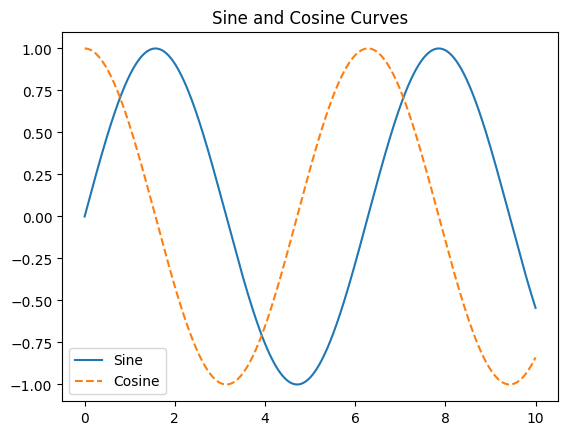

In [8]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(0, 10, 10000)

fig = plt.figure()
plt.plot(x, np.sin(x), '-', label='Sine')
plt.plot(x, np.cos(x), '--', label='Cosine')

# 제목과 범례 추가
plt.title("Sine and Cosine Curves")
plt.legend();

In [6]:
s90 = np.sin(90)
c90 = np.cos(90)
print(s90, c90)

0.8939966636005579 -0.4480736161291701


In [7]:
import math

def degrees_to_radians(degrees):
    """
    60분법(도, Degrees)을 호도법(라디안, Radians)으로 변환하는 함수
    """
    return math.radians(degrees)

# 직접 수식(도 * pi / 180)으로 변환하는 방법
def degrees_to_radians_manual(degrees):
    return degrees * (math.pi / 180)

# 테스트 코드
test_deg = 180
print(f"{test_deg}도는 호도법으로 {degrees_to_radians(test_deg)} 라디안입니다. (pi = {math.pi})")

180도는 호도법으로 3.141592653589793 라디안입니다. (pi = 3.141592653589793)


In [ ]:
z = np.

### NumPy에서 복소수(Complex Number) 표현하기

파이썬 및 NumPy에서는 허수 단위로 `i` 대신 **`j`**를 사용합니다.
복소수 배열을 생성할 때는 다음과 같은 방법을 사용할 수 있습니다.

In [1]:
import numpy as np

# 1. 'j' 표기법을 사용하여 직접 복소수 배열 생성
z1 = np.array([1 + 2j, 3 - 4j, 5j])
print("복소수 배열 z1:", z1)
print("z1의 타입:", z1.dtype)

# 2. dtype을 complex로 명시하여 생성
z2 = np.array([1, 2, 3], dtype=complex)
print("실수를 복소수형으로 변환한 z2:", z2)

# 3. 복소수의 실수부(real)와 허수부(imag) 추출 및 켤레복소수(conj)
print("z1의 실수부:", z1.real)
print("z1의 허수부:", z1.imag)
print("z1의 켤레복소수:", z1.conj())

복소수 배열 z1: [1.+2.j 3.-4.j 0.+5.j]
z1의 타입: complex128
실수를 복소수형으로 변환한 z2: [1.+0.j 2.+0.j 3.+0.j]
z1의 실수부: [1. 3. 0.]
z1의 허수부: [ 2. -4.  5.]
z1의 켤레복소수: [1.-2.j 3.+4.j 0.-5.j]


### NumPy로 고유값(Eigenvalues) 및 고유벡터(Eigenvectors) 구하기

NumPy에서는 `numpy.linalg.eig` 함수를 사용하여 정방행렬(Square matrix)의 고유값과 고유벡터를 계산할 수 있습니다.

In [19]:
import numpy as np

# 1. 2x2 정방행렬 정의
A = np.array([[2, 1,1],
              [2, 3, 2],
              [1,1,2]])

# 2. 고유값과 고유벡터 계산
eigenvalues, eigenvectors = np.linalg.eig(A)

print("행렬 A:")
print(A)
print("\n고유값 (Eigenvalues) :", eigenvalues)
print("\n고유벡터 (Eigenvectors, 각 열이 고유벡터에 해당) :")
print(eigenvectors)

# 검증: A * v = lambda * v
# 첫 번째 고유값과 고유벡터 검증
lmbda = eigenvalues[1]
v = eigenvectors[:, 1]

print("\n--- 검증 (A * v == lambda * v) ---")
print("A * v      :", np.dot(A, v))
print("lambda * v :", lmbda * v)

행렬 A:
[[2 1 1]
 [2 3 2]
 [1 1 2]]

고유값 (Eigenvalues) : [1. 5. 1.]

고유벡터 (Eigenvectors, 각 열이 고유벡터에 해당) :
[[-0.80178373  0.40824829 -0.29474362]
 [ 0.53452248  0.81649658 -0.51205571]
 [ 0.26726124  0.40824829  0.80679933]]

--- 검증 (A * v == lambda * v) ---
A * v      : [2.04124145 4.0824829  2.04124145]
lambda * v : [2.04124145 4.0824829  2.04124145]


In [16]:
eigenvectors[:,1]

array([-0.70710678,  0.70710678])

In [20]:
import sympy as sp

# 1. 기호 변수 정의
a, b, c, d = sp.symbols('a b c d')

# 2. 행렬 정의
A = sp.Matrix([
    [a + 1, b,     c,     d    ],
    [a,     b + 1, c,     d    ],
    [a,     b,     c + 1, d    ],
    [a,     b,     c,     d + 1]
])

# 3. 행렬식(Determinant) 계산
det_A = A.det()

# 4. 식 단순화 및 출력
det_A_simplified = sp.simplify(det_A)
print(f"행렬식 결과: {det_A_simplified}")

행렬식 결과: a + b + c + d + 1


In [2]:
import sympy as sp

# 1. 기호 변수 정의
t = sp.Symbol('t', real=True)

# 2. 벡터 r(t) 정의 (i, j, k 성분을 열벡터로 표현)
r = sp.Matrix([
    t**2 + 2*t,
    -3 * sp.exp(2*t),
    2 * sp.sin(t)
])

# (1) dr/dt 계산 및 t=0 대입
dr_dt = r.diff(t)
dr_dt_0 = dr_dt.subs(t, 0)

# (2) |dr/dt| at t=0 계산 (크기/절댓값)
norm_dr_dt_0 = dr_dt_0.norm()

# (3) d^2r/dt^2 계산 및 t=0 대입
d2r_dt2 = r.diff(t, 2)
d2r_dt2_0 = d2r_dt2.subs(t, 0)

# (4) |d^2r/dt^2| at t=0 계산
norm_d2r_dt2_0 = d2r_dt2_0.norm()

# 결과 출력
print("(1) dr/dt at t=0     :", dr_dt_0.T)
print("(2) |dr/dt| at t=0   :", norm_dr_dt_0)
print("(3) d^2r/dt^2 at t=0 :", d2r_dt2_0.T)
print("(4) |d^2r/dt^2| at t=0:", norm_d2r_dt2_0)

(1) dr/dt at t=0     : Matrix([[2, -6, 2]])
(2) |dr/dt| at t=0   : 2*sqrt(11)
(3) d^2r/dt^2 at t=0 : Matrix([[2, -12, 0]])
(4) |d^2r/dt^2| at t=0: 2*sqrt(37)


In [3]:
import sympy as sp

# 1. 기호 변수 및 기본 함수 정의
x = sp.Symbol('x', real=True)

def g1(x_val):
    return sp.sin(x_val)

def g2(x_val):
    return x_val**2 + 1

# 2. 합성함수 정의
f1 = g1(g2(x))  # g1(g2(x))
f2 = g2(g1(x))  # g2(g1(x))

# 결과 출력
print(f"f1(x) = {f1}")
print(f"f2(x) = {f2}")

f1(x) = sin(x**2 + 1)
f2(x) = sin(x)**2 + 1


In [4]:
# 1. 독립변수 x 및 미지함수 y(x) 정의
x = sp.Symbol('x')
y = sp.Function('y')(x)

# 2. 미분방정식 4*y*y' + x = 0 정의
ode = sp.Eq(4 * y * y.diff(x) + x, 0)

# 3. 일반해 구하기
sol = sp.dsolve(ode, y)

# 결과 출력
print(sol)

[Eq(y(x), -sqrt(C1 - x**2)/2), Eq(y(x), sqrt(C1 - x**2)/2)]


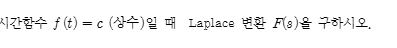

In [5]:
import sympy as sp

# 1. 기호 변수 정의 (시간 t, 복소주파수 s, 상수 c)
t = sp.Symbol('t', positive=True)
s = sp.Symbol('s', positive=True)
c = sp.Symbol('c')

# 2. 시간함수 f(t) = c 정의
f_t = c

# 3. 라플라스 변환 수행 (결과는 (F(s), plane, cond) 튜플 형태 반환)
F_s, _, _ = sp.laplace_transform(f_t, t, s)

# 결과 출력
print(f"F(s) = {F_s}")  # c/s


F(s) = c/s


Note that when saving your figure, it is not necessary to use `plt.show` or related commands discussed earlier.

#### MATLAB-style Interface

Matplotlib was originally conceived as a Python alternative for MATLAB users, and much of its syntax reflects that fact.
The MATLAB-style tools are contained in the `pyplot` (`plt`) interface.
For example, the following code will probably look quite familiar to MATLAB users (the following figure shows the result):

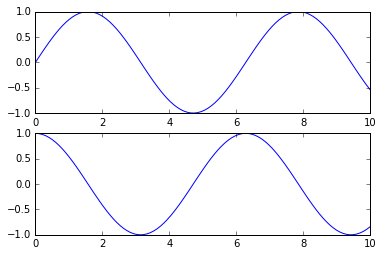

In [ ]:
plt.figure()  # create a plot figure

# create the first of two panels and set current axis
plt.subplot(2, 1, 1) # (rows, columns, panel number)
plt.plot(x, np.sin(x))

# create the second panel and set current axis
plt.subplot(2, 1, 2)
plt.plot(x, np.cos(x));

It is important to recognize that this interface is *stateful*: it keeps track of the "current" figure and axes, which are where all `plt` commands are applied.
You can get a reference to these using the `plt.gcf` (get current figure) and `plt.gca` (get current axes) routines.

While this stateful interface is fast and convenient for simple plots, it is easy to run into problems.
For example, once the second panel is created, how can we go back and add something to the first?
This is possible within the MATLAB-style interface, but a bit clunky.
Fortunately, there is a better way.

#### Object-oriented interface

The object-oriented interface is available for these more complicated situations, and for when you want more control over your figure.
Rather than depending on some notion of an "active" figure or axes, in the object-oriented interface the plotting functions are *methods* of explicit `Figure` and `Axes` objects.
To re-create the previous plot using this style of plotting, as shown in the following figure, you might do the following:

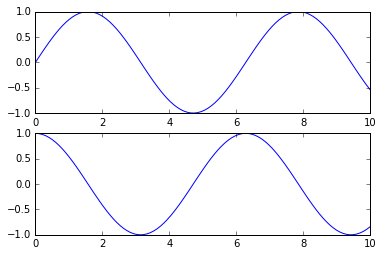

In [ ]:
# First create a grid of plots
# ax will be an array of two Axes objects
fig, ax = plt.subplots(2)

# Call plot() method on the appropriate object
ax[0].plot(x, np.sin(x))
ax[1].plot(x, np.cos(x));

For simpler plots, the choice of which style to use is largely a matter of preference, but the object-oriented approach can become a necessity as plots become more complicated.
Throughout the following chapters, we will switch between the MATLAB-style and object-oriented interfaces, depending on what is most convenient.
In most cases, the difference is as small as switching `plt.plot` to `ax.plot`, but there are a few gotchas that I will highlight as they come up in the following chapters.